## Business Problem:

### Make the model identify the ticket type from any new custormer support tickets based on its description

**Input (X):** Ticket Description

**Output (Y):** Ticket Type

**Model Type:** Classification

**Business Use:** The support team can use the predicted ticket type to automatically categorize incoming customer tickets and route them to the appropriate support team or workflow.

In [7]:
# Cell 1 — Data loading and inspection
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/customer_support_tickets_clean.csv")
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical Issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,Not Resolved,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical Issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,Not Resolved,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical Issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing Inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing Inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [8]:
df.shape

(8469, 17)

In [9]:
df.columns

Index(['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age',
       'Customer Gender', 'Product Purchased', 'Date of Purchase',
       'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status',
       'Resolution', 'Ticket Priority', 'Ticket Channel',
       'First Response Time', 'Time to Resolution',
       'Customer Satisfaction Rating'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    8469 non-null   object 
 12  Ticket Priority               8469 non-null   object 
 13  Tic

Number of invalid Tickets due to missing Ticket Type: 0

Ticket Count by Type
Ticket Type
Refund Request          1752
Technical Issue         1747
Cancellation Request    1695
Product Inquiry         1641
Billing Inquiry         1634
Name: count, dtype: int64

Percentage by type:
Ticket Type
Refund Request          20.69%
Technical Issue         20.63%
Cancellation Request    20.01%
Product Inquiry         19.38%
Billing Inquiry         19.29%
Name: proportion, dtype: object

The most common ticket type is Refund Request with 1752 tickets.
The least common ticket type is Billing Inquiry with 1634 tickets.
The difference of ticket percentage between the most and the leas common ticket types is 1.39%.


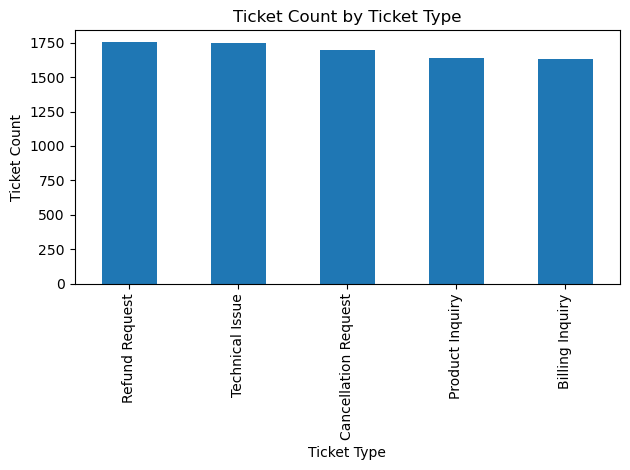

In [11]:
# Cell 2 — Checking for imbalances between the ticket types
invalid = df["Ticket Type"].fillna("").str.strip().eq("").sum()
print(f"Number of invalid Tickets due to missing Ticket Type: {invalid}")
freq = df["Ticket Type"].value_counts(dropna=False)
percentage = df["Ticket Type"].value_counts(dropna=False, normalize=True) * 100

 
# 1. Tickets per ticket type
print()
print("Ticket Count by Type")
print(freq)
print()

# 2. Percentage per ticket type
print("Percentage by type:")
print(percentage.map(lambda x: f"{x:.2f}%"))
print()

print(f"The most common ticket type is {freq.idxmax()} with {freq.max()} tickets.")
print(f"The least common ticket type is {freq.idxmin()} with {freq.min()} tickets.")
print(f"The difference of ticket percentage between the most and the leas common ticket types is {(percentage.max() - percentage.min()):.2f}%.")

freq.plot(
    kind="bar",
    title= "Ticket Count by Ticket Type"
)

plt.xlabel("Ticket Type")
plt.ylabel("Ticket Count")
plt.tight_layout()
plt.show()


In [12]:
# Cell 3 — Check the text feature
invalid = df["Ticket Description"].fillna("").str.strip().eq("").sum()
print(f"Number of invalid Tickets due to missing Ticket Description: {invalid}")
description_lengths = df["Ticket Description"].str.len()
description_lengths.describe()


Number of invalid Tickets due to missing Ticket Description: 0


count    8469.000000
mean      289.821939
std        43.593954
min       151.000000
25%       273.000000
50%       298.000000
75%       318.000000
max       397.000000
Name: Ticket Description, dtype: float64

## Day 22 Conclusions

- There are no missing, empty, or whitespace-only values in the Ticket Type and Ticket Description columns.
The tickets are distributed relatively evenly across the five ticket types.
- Refund requests are the most frequent category with 1,752 tickets (20.69%), while billing inquiries are the least frequent with 1,634 tickets (19.29%).
- The difference between the largest and smallest classes is only 1.39 percentage points, indicating that there is no substantial class imbalance in the target variable.
- Based on the class distribution and the absence of unusable values in the input and target columns, the dataset appears suitable to proceed to the model-development stage.